# Training experiment A: Optimal Patch Cap

Launcher for the MGMT training pipeline: it picks a backbone and a validation fold, runs each experiment below through `python -m training.run train`, and reads the run folders back. Training logic lives in `training/`, so everything here is settings and reading results.

Each experiment is a list of `--set key=value` overrides on `configs/train.yaml` and `configs/backbones/<backbone>.yaml`. A `smoke` run trains on the validation patients to show the pipeline runs end to end; its record is marked invalid for results. A real run needs `macenko_reference_patch_ids` set for the fold. Values for Experiment A (tiles per patient) and Experiment B (JPEG quality) are not decided yet, so they are not listed. Add them as rows when they are.

Loaded index records: 117
Using column 'accept' for patch/tile counts.
Filtered out 1 patient(s) with zero acceptable patches. Remaining: 116

--- Cleaned Patient Patch Count Summary ---
count      116.000000
mean     18087.681034
std      22342.958978
min        413.000000
25%       2979.250000
50%       8807.000000
75%      24507.750000
max      97085.000000
Name: num_patches, dtype: float64

Figure successfully saved to ../experiments/figures/patient_patch_distribution_cleaned.png


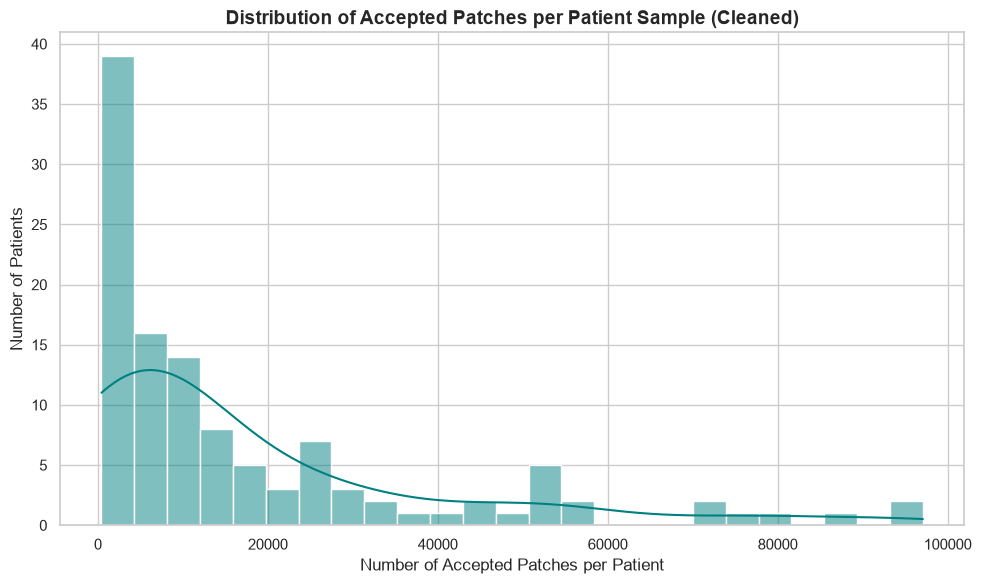

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_cleaned_patient_patch_distribution(index_path="../manifests/patient_index.csv", labels_path="../manifests/patient_labels.csv"):
    """Loads patient manifests, filters out samples with zero accepted patches, and plots the distribution."""
    
    # Check alternate paths if running from root vs notebooks directory
    if not os.path.exists(index_path):
        index_path = "manifests/patient_index.csv"
        labels_path = "manifests/patient_labels.csv"

    if not os.path.exists(index_path):
        print(f"Manifest file not found at {index_path}. Please check your working directory.")
        return

    # Load manifests
    df_index = pd.read_csv(index_path)
    print(f"Loaded index records: {len(df_index)}")
    
    df_labels = None
    if os.path.exists(labels_path):
        df_labels = pd.read_csv(labels_path)

    # Identify the tile acceptance count column
    tile_col = None
    for col in ['accept', 'tissue_tiles', 'num_patches', 'accepted_tiles', 'patch_count']:
        if col in df_index.columns:
            tile_col = col
            break

    if tile_col is None:
        print("\nCould not find a valid tile count column. Available columns:")
        print(list(df_index.columns))
        return

    print(f"Using column '{tile_col}' for patch/tile counts.")

    # Group by patient_id and aggregate total accepted patches
    if 'patient_id' in df_index.columns:
        patient_counts = df_index.groupby('patient_id')[tile_col].sum().reset_index(name='num_patches')
    else:
        print("Error: 'patient_id' column not found in index CSV.")
        return

    # Filter out patients/slides with zero acceptable patches
    initial_count = len(patient_counts)
    patient_counts = patient_counts[patient_counts['num_patches'] > 0]
    filtered_count = initial_count - len(patient_counts)
    print(f"Filtered out {filtered_count} patient(s) with zero acceptable patches. Remaining: {len(patient_counts)}")

    # Merge with labels/cohort info if available
    if df_labels is not None and 'patient_id' in df_labels.columns:
        patient_counts = pd.merge(patient_counts, df_labels, on='patient_id', how='left')

    # Print summary statistics to the console
    print("\n--- Cleaned Patient Patch Count Summary ---")
    print(patient_counts['num_patches'].describe())

    # Set up the plotting style
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(10, 6))
    
    # Create histogram with KDE curve (hue by cohort if available)
    if df_labels is not None and 'cohort' in patient_counts.columns:
        sns.histplot(data=patient_counts, x='num_patches', hue='cohort', kde=True, bins=25, multiple="stack")
        plt.title('Distribution of Accepted Patches per Patient (Cleaned Multi-Cohort)', fontsize=14, fontweight='bold')
    else:
        sns.histplot(patient_counts['num_patches'], kde=True, bins=25, color='teal')
        plt.title('Distribution of Accepted Patches per Patient Sample (Cleaned)', fontsize=14, fontweight='bold')

    plt.xlabel('Number of Accepted Patches per Patient', fontsize=12)
    plt.ylabel('Number of Patients', fontsize=12)
    
    # Save the figure
    os.makedirs("../experiments/figures", exist_ok=True)
    output_path = "../experiments/figures/patient_patch_distribution_cleaned.png"
    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    print(f"\nFigure successfully saved to {output_path}")
    
    plt.show()

if __name__ == "__main__":
    plot_cleaned_patient_patch_distribution()

In [8]:
import os
import sys
import time
from pathlib import Path
import pandas as pd
import torch
from training import report

# Set up working directory and path
REPO = Path.cwd() if (Path.cwd() / "training").is_dir() else Path.cwd().parent
os.chdir(REPO)
sys.path.insert(0, str(REPO))

In [9]:
#Tile cap utilization
package_dir = REPO / "data" / "packages" / "B_qc-v5"
index_csv = package_dir / "patient_index.csv"

if index_csv.exists():
    patients_df = pd.read_csv(index_csv)
    tile_col = 'model_tiles_stored' if 'model_tiles_stored' in patients_df.columns else 'tissue_tiles'
    tiles = patients_df[tile_col]

    caps = [512, 1024, 2048, 4096]
    print("--- Tile Cap Utilization Analysis ---")
    for cap in caps:
        truncated_patients = (tiles > cap).sum()
        pct = (truncated_patients / len(tiles)) * 100
        print(f"Cap {cap:4d}: {truncated_patients} patients ({pct:.1f}% of cohort) will be truncated.")
    print("-" * 37)

--- Tile Cap Utilization Analysis ---
Cap  512: 115 patients (98.3% of cohort) will be truncated.
Cap 1024: 109 patients (93.2% of cohort) will be truncated.
Cap 2048: 96 patients (82.1% of cohort) will be truncated.
Cap 4096: 77 patients (65.8% of cohort) will be truncated.
-------------------------------------


In [13]:
BACKBONE = "convnext_v2_tcaffeinate -d"        # ConvNeXt V2 backbone
FOLD = 0                          # Validation fold, 0 to 4
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")

EXPERIMENTS = {
    "cap_512": [
        "max_tiles_per_patient=512",
        "max_eval_tiles_per_patient=512",
        "stages_real=[{learning_rate: 1.0e-5, epochs: 5, class_weighted: true}]"
    ],
    "cap_1024": [
        "max_tiles_per_patient=1024",
        "max_eval_tiles_per_patient=1024",
        "stages_real=[{learning_rate: 1.0e-5, epochs: 5, class_weighted: true}]"
    ],
    "cap_2048": [
        "max_tiles_per_patient=2048",
        "max_eval_tiles_per_patient=2048",
        "stages_real=[{learning_rate: 1.0e-5, epochs: 5, class_weighted: true}]"
    ],
    "cap_4096": [
        "max_tiles_per_patient=4096",
        "max_eval_tiles_per_patient=4096",
        "stages_real=[{learning_rate: 1.0e-5, epochs: 5, class_weighted: true}]"
    ]
}

SELECTED = ["cap_512", "cap_1024", "cap_2048", "cap_4096"]

In [ ]:
#Run Sweeps with Timing & VRAM Tracking (Point 2 - MPS Optimized)
runs = {}
for name in SELECTED:
    print(f"\n--- Starting training for: {name} ---")
    start_time = time.time()
    
    # Reset stats only if using CUDA (MPS tracks current allocated memory directly)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_allocated()
        
    # Launch training run
    runs[name] = report.launch(BACKBONE, FOLD, EXPERIMENTS[name], DEVICE)
    
    elapsed_time = time.time() - start_time
    print(f"Completed {name} in {elapsed_time / 60:.2f} minutes.")
    
    # Report peak memory usage
    if DEVICE == "mps":
        peak_mem = torch.mps.current_allocated_memory() / (1024 ** 2)
        print(f"Peak MPS Allocated Memory: {peak_mem:.2f} MB")
    elif DEVICE == "cuda":
        peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 2)
        print(f"Peak CUDA VRAM Usage: {peak_vram:.2f} MB")


--- Starting training for: cap_512 ---


In [ ]:
# Summarize metrics (Loss, AUROC, etc.)
report.summarize(runs)

In [ ]:
# Plot and save validation/training curves
figure = report.plot_curves(runs)
os.makedirs(REPO / "data" / "runs", exist_ok=True)
figure.savefig(REPO / "data" / "runs" / f"curves_{BACKBONE}_fold{FOLD}.png", dpi=150)